# PHerc0846A Inference

Forward-only inference with a flat depth-13 surface. `DEPTH_OFFSET = -1` selects slices 9-16; change the offset immediately below `CHECKPOINT` in the settings cell. Saved checkpoint geometry and normalization are replayed, while this offset explicitly overrides saved offsets.

Run the setup cells, then any individual segment cell. The final cell processes the remaining PHerc0846A quick patches into one `quick_patches` subfolder, excluding segments with individual cells. Figures contain prediction and the composite of the selected input slices. Volumes and masks must already be assembled; this notebook does not reverse volumes, detect surfaces, or modify labels.

In [1]:
# [] = one depth; [low, high] = ensemble every offset low..high around the usual depth ([-3, 3] -> 7 depths)
depth_ensemble = []
# how ensemble depths combine: 'z-score' (top-2), 'max', 'mid-boost' (k=3), 'mean' (top-2); '' = 'mid-boost'
ensemble_method = ''

CHECKPOINT = "/vesuvius/models/runs_iter2/iter2_cue_dropout_labelsv3_seed17/model_epoch_10.pth"
DEPTH_OFFSET = -1

FLAT_DEPTH = 13
EVAL_STRIDE = 32
PREVIEW_DOWNSCALE = 10  # previews shrink by this factor; saved figures stay full size
DEVICE = "auto"

import os
import sys
from pathlib import Path

REPO = Path("/vesuvius")
# nonml_ink.py (imported by utils.precomputed_asf) lives in old/
for _path in (REPO, REPO / "old"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
os.chdir(REPO)


In [2]:
# a long-lived kernel must pick up the input_cue field and the 4-cue stem before the model is built
import importlib
import utils.config
import utils.prefilter
import utils.model

for _module in (utils.config, utils.prefilter, utils.model):
    importlib.reload(_module)


In [3]:
import gc
import json
import tempfile
import types

import cv2
import numpy as np
import torch
import zarr
from IPython.display import display
from PIL import Image

from utils.config import Config, ScrollConfig, resolve_run_config
from utils.fast_figure import colorize, gray_rgb, save_panel_grid
from utils.model import create_model
from utils.norm import (
    ANCHOR_GAP_LEVEL, ANCHOR_PAPYRUS_LEVEL, UNIFIED_CACHE_PATH,
    compute_norm, compute_surface_anchors, load_cached_norm,
)
from utils.platform import get_zarr_dir
from utils.visualizer import TensorboardVisualizer, predict_tiles

Image.MAX_IMAGE_PIXELS = None
MODEL_PATH = Path(CHECKPOINT).resolve()
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint is missing: {MODEL_PATH}")
RUN_CONFIG, RUN_CONFIG_PATH = resolve_run_config(MODEL_PATH)
C = Config()
for section in ("data", "model"):
    for name, value in RUN_CONFIG[section].items():
        if section == "data" and name == "scrolls":
            C.data.scrolls = [ScrollConfig(**item) for item in value]
        elif name != "probe_rois" and hasattr(getattr(C, section), name):
            setattr(getattr(C, section), name, value)
C.model.compile_model = False
C.tra.supcon = False
C.tra.dann = False
C.device = ("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else DEVICE
C.data.eval_stride = EVAL_STRIDE
C.data.surface_window_offset = int(DEPTH_OFFSET)
C.data.surface_window_offset_by_scroll = {}
ZARR_DIR = Path(get_zarr_dir())
C.data.zarr_path = str(ZARR_DIR)
DEPTH = int(C.data.depth)
if DEPTH != 8 or not C.model.surface_teacher_input or not C.data.surface_relative_depth_window:
    raise ValueError("Select a literal-surface, eight-slice checkpoint")
if EVAL_STRIDE <= 0 or EVAL_STRIDE > C.model.multitile_grid * C.model.multitile_subtile:
    raise ValueError("Inference stride must be positive and no larger than the prediction center")
WINDOW_START = FLAT_DEPTH - (DEPTH - 1) // 2 + int(DEPTH_OFFSET)
WINDOW_END = WINDOW_START + DEPTH
NORM_MODE = str(C.data.norm_mode)
MODEL_NAME = f"{MODEL_PATH.parent.parent.name}_{MODEL_PATH.parent.name}_{MODEL_PATH.stem}"
OUT_DIR = REPO / "output" / "0846A" / MODEL_NAME / f"offset_{DEPTH_OFFSET:+d}"
CACHE_ROOT = REPO / "_ves_tmp" / "0846A_inference"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

# every patch is read with a flat depth-FLAT_DEPTH surface (load_inputs); detected surfaces are never used
MAIN_PATCHES = {
    "auto_grown_20260927134928530_abf": {"zid": "20260927134928", "norm_id": 20260927134931},
    "auto_grown_20261012065803387_straight_abf": {"zid": "20261012065810", "norm_id": 20261012065811},
    "auto_grown_20261012065803387_straight_abf_m28": {"zid": "20261012065812", "norm_id": 20261012065813},
    "auto_grown_20261012073244544_abf": {"zid": "20261012073244", "norm_id": 20261012073246},
    "auto_grown_20261012073244544_abf_p29": {"zid": "20261012073249", "norm_id": 20261012073250},
    "auto_grown_20261012081237255_abf": {"zid": "20261012081237", "norm_id": 20261012081238},
    "auto_grown_20261014084609861_straight_abf": {"zid": "20261014084610", "norm_id": 20261014084611},
    "auto_grown_20261012065803387_straightened2_abf": {"zid": "20261012065814", "norm_id": 20261012065815},
    "auto_grown_20261012065803387_straightened2_abf_in_1": {"zid": "20261012065816", "norm_id": 20261012065817},
    "auto_grown_20261012065803387_straightened2_abf_out_1": {"zid": "20261012065818", "norm_id": 20261012065819},
    "auto_grown_20261012065803387_straightened2_abf_out_2": {"zid": "20261012065820", "norm_id": 20261012065821},
    "auto_grown_20261012065803387_straightened2_abf_out_3": {"zid": "20261012065822", "norm_id": 20261012065823},
    "auto_grown_20261012065803387_straightened2_abf_out_4": {"zid": "20261012065824", "norm_id": 20261012065825},
    "auto_grown_20261012065803387_straightened2_abf_out_5": {"zid": "20261012065826", "norm_id": 20261012065827},
    # PHerc0009B (trained): its stored surface labels and window offset (0), not the flat depth-13 surface of the 0846A patches
    "PHerc0009B_20250919125754": {"zid": "20250919125754", "norm_id": 20250919125754,
                                  "surface_dir": REPO / "surface_labels" / "20250919125754", "offset": 0},
}
for patch in MAIN_PATCHES.values():
    patch["mask_dir"] = REPO / "masks"
WINNING = "auto_grown_20261012065803387_straightened2_abf"
TRAINING_NAMES = (
    "auto_grown_20260927134928530_abf", "auto_grown_20261012073244544_abf",
    "auto_grown_20261012065803387_straight_abf_m28",
    "auto_grown_20261012065803387_straightened2_abf_in_1", "auto_grown_20261012065803387_straightened2_abf_out_1",
    "auto_grown_20261012065803387_straightened2_abf_out_2", "auto_grown_20261012065803387_straightened2_abf_out_3",
    "PHerc0009B_20250919125754",
)
HOLDOUT_NAMES = ("auto_grown_20261012065803387_straightened2_abf_out_4",
                 "auto_grown_20261012065803387_straightened2_abf_out_5",
                 "auto_grown_20260926074031926_abf", "auto_grown_20260927143929299_abf", "auto_grown_20260927154033403_abf")
QUICK_ROOT = REPO / "tifxyz" / "quick_patches_from_D" / "PHerc0846A"
if not QUICK_ROOT.is_dir():
    raise FileNotFoundError(QUICK_ROOT)
QUICK_PATCHES = {
    path.name: {"zid": path.name, "mask_dir": REPO / "masks" / "extras"}
    for path in sorted(QUICK_ROOT.iterdir()) if path.is_dir() and (path / "x.tif").is_file()
}
INDIVIDUAL_NAMES = (WINNING, *TRAINING_NAMES, *HOLDOUT_NAMES)
PATCHES = {**QUICK_PATCHES, **MAIN_PATCHES}
REMAINING_QUICK_NAMES = tuple(name for name in QUICK_PATCHES if name not in INDIVIDUAL_NAMES)
MODEL = None


def supervision_role(name):
    patch = PATCHES[name]
    identities = {name, str(patch["zid"]), str(patch.get("norm_id", ""))}
    domains = C.data.train_scroll_dict or {}
    excluded = set(C.data.holdout_domains or [])
    trained = {str(sid) for domain, ids in domains.items() if domain not in excluded for sid in ids}
    if not domains:
        trained = {str(scroll.scroll_id) for scroll in C.data.scrolls}
    return "TRAIN (subject to saved label split)" if identities & trained else "VIS-ONLY (not supervised by this checkpoint)"


print(f"Model: {MODEL_PATH}\nConfig: {RUN_CONFIG_PATH}\nForward slices: {WINDOW_START}-{WINDOW_END - 1} (flat depth {FLAT_DEPTH})")
print(f"Output: {OUT_DIR}\nIndividual segments: {len(INDIVIDUAL_NAMES)}; remaining quick patches: {len(REMAINING_QUICK_NAMES)}")


2026-10-20 23:11:47.584312: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-20 23:11:47.586045: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-20 23:11:47.589258: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-20 23:11:47.597214: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792537907.610196  517979 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792537907.61

Model: /vesuvius/models/runs_iter2/iter2_cue_dropout_labelsv3_seed17/model_epoch_10.pth
Config: /vesuvius/models/runs_iter2/iter2_cue_dropout_labelsv3_seed17/config.json
Forward slices: 9-16 (flat depth 13)
Output: /vesuvius/output/0846A/runs_iter2_iter2_cue_dropout_labelsv3_seed17_model_epoch_10/offset_-1
Individual segments: 14; remaining quick patches: 33


In [4]:
# the checkpoint's input heads must be replayed from its run config (strict loading fails on a 3-head model otherwise)
if str(C.model.input_cue) != str(RUN_CONFIG["model"].get("input_cue") or ""):
    raise RuntimeError("input_cue was not replayed from the run config; restart the kernel")
print("input heads:", 4 if C.model.input_cue else 3, C.model.input_cue or "(raw, lcn, dz)")


input heads: 4 pre_clahe


In [5]:
def get_model():
    global MODEL
    if MODEL is None:
        model, parameter_count = create_model(C)
        state = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
        if "model_state_dict" in state:
            state = state["model_state_dict"]
        elif "state_dict" in state:
            state = state["state_dict"]
        state = {name.removeprefix("module.").removeprefix("_orig_mod."): value for name, value in state.items()}
        state = {name: value for name, value in state.items() if not name.startswith(("supcon_head.", "domain_head."))}
        model.load_state_dict(state, strict=True)
        model.eval()
        MODEL = model
        print(f"Loaded {parameter_count:,} parameters on {C.device}")
    return MODEL


def input_paths(name):
    patch = PATCHES[name]
    volume_path = ZARR_DIR / f"{patch['zid']}.zarr"
    mask_path = patch["mask_dir"] / f"{patch['zid']}.png"
    missing = [str(path) for path in (volume_path, mask_path) if not path.exists()]
    if missing:
        raise FileNotFoundError("Assemble these inputs before inference: " + ", ".join(missing))
    return volume_path, mask_path


def flat_norm(patch, volume_path, mask_path, surface_depth, surface_confidence):
    if "norm_id" in patch and FLAT_DEPTH == 13:
        try:
            cached = load_cached_norm(patch["norm_id"], UNIFIED_CACHE_PATH, mode=NORM_MODE)
        except RuntimeError:
            cached = None
        if cached is not None:
            return cached
    if NORM_MODE == "raw255":
        return 0.0, 1.0, 0.0, 255.0
    private_cache = str(CACHE_ROOT / "global_norm.json")
    if NORM_MODE == "global":
        cached = load_cached_norm(patch["zid"], UNIFIED_CACHE_PATH, mode="global")
        cached = cached or load_cached_norm(patch["zid"], private_cache, mode="global")
        return cached or compute_norm(patch["zid"], str(ZARR_DIR), private_cache, mask_dir=str(patch["mask_dir"]))
    if NORM_MODE not in ("surface_anchor", "surface_anchor_knee"):
        raise ValueError(f"Unsupported normalization: {NORM_MODE}")
    attrs_path = volume_path / ".zattrs"
    signature = {
        "volume": str(volume_path.resolve()), "flat_depth": FLAT_DEPTH,
        "attrs_mtime": attrs_path.stat().st_mtime_ns if attrs_path.exists() else volume_path.stat().st_mtime_ns,
        "mask_mtime": mask_path.stat().st_mtime_ns, "shape": list(surface_depth.shape),
    }
    cache_path = CACHE_ROOT / f"{patch['zid']}_flat_anchors.json"
    if cache_path.is_file():
        cached = json.loads(cache_path.read_text())
        if cached.get("signature") == signature:
            return tuple(cached["norm"])
    with tempfile.TemporaryDirectory(dir=CACHE_ROOT) as temporary:
        surface_dir = Path(temporary) / str(patch["zid"])
        surface_dir.mkdir()
        np.save(surface_dir / "depth.npy", surface_depth)
        np.save(surface_dir / "confidence.npy", surface_confidence)
        anchors = compute_surface_anchors(patch["zid"], str(ZARR_DIR), surface_dir=temporary,
                                          mask_dir=str(patch["mask_dir"]))
    span = (anchors["papyrus"] - anchors["gap"]) / (ANCHOR_PAPYRUS_LEVEL - ANCHOR_GAP_LEVEL)
    lower = anchors["gap"] - ANCHOR_GAP_LEVEL * span
    norm = (0.0, 1.0, lower, lower + span)
    cache_path.write_text(json.dumps({"signature": signature, "norm": norm, "anchors": anchors}, indent=2))
    return norm


def flat_cue(patch, volume, mask):
    """precomputed cue map for a model with input_cue 'pre_clahe': the stored map of the patch's flat alias when there is
    one (the exact map training read), else computed from the loaded window and cached under CACHE_ROOT/cue."""
    from utils.precomputed_asf import cue_from_window

    stored = Path(C.data.cue_dir) / f"{patch.get('norm_id', patch['zid'])}.npy"
    if stored.is_file():
        return np.load(stored, mmap_mode="r")
    cached = CACHE_ROOT / "cue" / f"{patch['zid']}_s{WINDOW_START}.npy"
    if not cached.is_file():
        cached.parent.mkdir(parents=True, exist_ok=True)
        cue = cue_from_window(np.asarray(volume[WINDOW_START:WINDOW_END], dtype=np.float32), mask)
        np.save(cached, cue)
    return np.load(cached, mmap_mode="r")


# most recent patch's inputs, so consecutive cells on one patch skip the reload
_INPUT_CACHE = {}


def load_inputs(name):
    import time

    volume_path, mask_path = input_paths(name)
    key = (name, (volume_path / ".zarray").stat().st_mtime_ns, mask_path.stat().st_mtime_ns)
    if key in _INPUT_CACHE:
        return _INPUT_CACHE[key]
    _INPUT_CACHE.clear()
    gc.collect()
    source = zarr.open(str(volume_path), mode="r")
    if source.attrs.get("layers_reversed_from") or source.attrs.get("facing_reversed"):
        raise ValueError(f"Forward inference requires the original volume: {volume_path}")
    with Image.open(mask_path) as image:
        mask = np.asarray(image.convert("L")) > 0
    height, width = mask.shape
    if tuple(source.shape[1:]) != (height, width):
        raise ValueError(f"Mask and volume frames differ for {name}: {mask.shape} vs {source.shape}")
    if not mask.any():
        raise ValueError(f"Invalid mask for {name}")
    started = time.time()
    # small zarr chunks make the overlapping context-strip reads decompress each chunk many times
    volume = np.ascontiguousarray(source[:])
    volume.setflags(write=False)
    print(f"[preload] {name}: {volume.shape} {volume.nbytes / 1024**3:.2f} GiB in RAM in {time.time() - started:.1f}s")
    patch = PATCHES[name]
    offset = int(patch.get("offset", DEPTH_OFFSET))
    if patch.get("surface_dir"):
        surface_depth = np.load(Path(patch["surface_dir"]) / "depth.npy")
        surface_confidence = np.load(Path(patch["surface_dir"]) / "confidence.npy")
        if surface_depth.shape != mask.shape:
            raise ValueError(f"Surface labels {surface_depth.shape} differ from the mask {mask.shape} for {name}")
    else:
        surface_depth = np.where(mask, FLAT_DEPTH, 255).astype(np.uint8)
        surface_confidence = np.where(mask, 255, 0).astype(np.uint8)
    valid_depth = surface_depth[(surface_depth != 255) & mask]
    win_start = int(np.median(valid_depth)) - (DEPTH - 1) // 2 + offset
    win_end = win_start + DEPTH
    coords = TensorboardVisualizer._gen_tile_coords(
        types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end),
        (0, height), (0, width), mask, z_step=DEPTH,
    )
    if not coords or any(coordinate[0] != 0 for coordinate in coords):
        raise ValueError(f"Expected one nonempty surface-relative pass for {name}")
    if win_start < 0 or win_end > source.shape[0]:
        raise ValueError(f"Invalid depth window {win_start}:{win_end} for {name}")
    norm = flat_norm(PATCHES[name], volume_path, mask_path, surface_depth, surface_confidence)
    cue = flat_cue(PATCHES[name], volume, mask) if str(C.model.input_cue) == "pre_clahe" else None
    _INPUT_CACHE[key] = {"volume": volume, "mask": mask, "surface_depth": surface_depth,
                         "surface_confidence": surface_confidence, "coords": coords, "norm": norm, "cue": cue,
                         "offset": offset, "win_start": win_start, "win_end": win_end}
    return _INPUT_CACHE[key]


In [6]:
import importlib
import utils.fast_figure as figure_utils
import utils.depth_ensemble as depth_ensemble_utils

importlib.reload(figure_utils)
importlib.reload(depth_ensemble_utils)
depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)

PREDICTIONS = {}  # last prediction grid of each rendered patch, for cells that post-process it


def training_label_and_cue(name, inputs):
    """inklabel (trainer's label dir) and asf_morph cue of a training patch, both in the mask frame."""
    patch = PATCHES[name]
    label_path = Path(C.data.inklabel_dir) / f"{patch['norm_id']}.png"
    with Image.open(label_path) as image:
        label = np.asarray(image.convert("L")) > 0
    cue = inputs["cue"]
    if cue is None:
        cue = flat_cue(patch, inputs["volume"], inputs["mask"])
    if label.shape != inputs["mask"].shape or cue.shape != inputs["mask"].shape:
        raise ValueError(f"{name}: mask {inputs['mask'].shape}, label {label.shape}, cue {cue.shape} differ")
    return label, np.asarray(cue)


def render(name, output_subdir=None, preview=True):
    from utils.fast_figure import orient_display, red_overlay

    inputs = load_inputs(name)
    model = get_model()
    print(f"{name}: {supervision_role(name)}")
    height, width = inputs["mask"].shape
    offset, WINDOW_START, WINDOW_END = inputs["offset"], inputs["win_start"], inputs["win_end"]
    offsets, method = depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)
    prediction = depth_ensemble_utils.ensemble_predict(predict_tiles, offsets, method)(
        C, model, inputs["volume"], inputs["mask"], inputs["coords"],
        (0, height), (0, width), C.data.d_start, name, *inputs["norm"],
        surface_depth_map=inputs["surface_depth"],
        surface_confidence_map=inputs["surface_confidence"],
        surface_depth_offset=offset, cue_map=inputs["cue"],
    )
    PREDICTIONS[name] = np.array(prediction, dtype=np.float32)
    ensemble_label = depth_ensemble_utils.describe([offset + o for o in offsets], method)
    projection = np.asarray(inputs["volume"][WINDOW_START:WINDOW_END]).max(axis=0)
    composite = np.clip(projection, 0, 255).astype(np.uint8) * inputs["mask"]
    display_prediction = orient_display(prediction, name)
    display_composite = orient_display(composite, name)
    pred_title = f"{name} | {ensemble_label or f'forward {WINDOW_START}-{WINDOW_END - 1}'}"
    pred_rgb = colorize(display_prediction, "gray_r", (0.78, 0.86, 0.95))
    composite_panel = (f"composite {WINDOW_START}-{WINDOW_END - 1}", gray_rgb(display_composite), cv2.INTER_AREA, 9.362)
    if name in TRAINING_NAMES:
        # 2x2: prediction | composite over prediction + red inklabel | asf_morph cue
        label, cue = training_label_and_cue(name, inputs)
        cell_hw = display_composite.shape
        pred_full = cv2.resize(pred_rgb, (cell_hw[1], cell_hw[0]), interpolation=cv2.INTER_NEAREST)
        overlay = red_overlay(pred_full, orient_display(label, name))
        panels = [
            [(pred_title, pred_full, cv2.INTER_AREA, None), composite_panel],
            [(f"{name} | inklabel overlay (red)", overlay, cv2.INTER_AREA, None),
             ("asf_morph cue", gray_rgb(orient_display(cue, name)), cv2.INTER_AREA, None)],
        ]
        del pred_full, overlay, label, cue
    else:
        panels = [[(pred_title, pred_rgb, cv2.INTER_NEAREST, None), composite_panel]]
    folder = OUT_DIR if output_subdir is None else OUT_DIR / output_subdir
    folder.mkdir(parents=True, exist_ok=True)
    output_path = folder / f"{name}.png"
    save_panel_grid(panels, display_composite.shape, str(output_path), gap_px=24)
    if preview:
        with Image.open(output_path) as saved:
            reduced = saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE),
                                    max(1, saved.height // PREVIEW_DOWNSCALE)), Image.Resampling.LANCZOS)
        display(reduced)
    print(f"Saved {output_path}")
    del inputs, prediction, projection, composite, display_prediction, display_composite, panels
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return output_path


def render_remaining_quick_patches():
    for name in REMAINING_QUICK_NAMES:
        input_paths(name)
    failures = {}
    outputs = []
    for index, name in enumerate(REMAINING_QUICK_NAMES, start=1):
        print(f"[{index}/{len(REMAINING_QUICK_NAMES)}] {name}")
        try:
            outputs.append(render(name, output_subdir="quick_patches", preview=False))
        except Exception as error:
            failures[name] = str(error)
            print(f"FAILED {name}: {error}")
    print(f"Saved {len(outputs)} quick-patch figures to {OUT_DIR / 'quick_patches'}")
    if failures:
        raise RuntimeError(f"Quick-patch failures: {failures}")
    return outputs


[preload] auto_grown_20261012065803387_straightened2_abf: (28, 2561, 4101) 0.55 GiB in RAM in 37.6s
Model parameters (nnunet3d_lcndz): 7,554,654


/usr/local/lib/python3.10/dist-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Loaded 7,554,654 parameters on cuda
auto_grown_20261012065803387_straightened2_abf: VIS-ONLY (not supervised by this checkpoint)
[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


[predict] auto_grown_20261012065803387_straightened2_abf done in 110.1s  predict 107.3s (97.4%)  read/wait   2.8s ( 2.6%)  [prefetch x3]


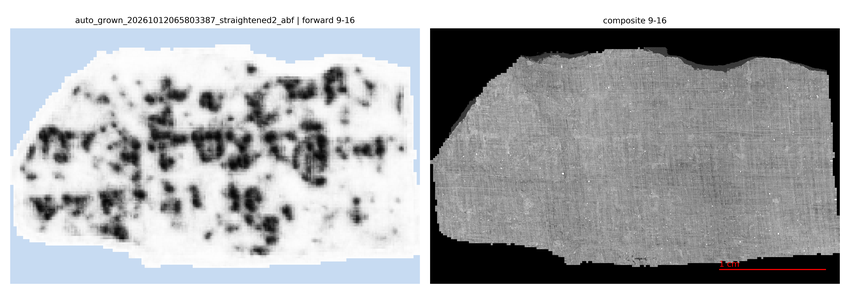

Saved /vesuvius/output/0846A/runs_iter2_iter2_cue_dropout_labelsv3_seed17_model_epoch_10/offset_-1/auto_grown_20261012065803387_straightened2_abf.png


PosixPath('/vesuvius/output/0846A/runs_iter2_iter2_cue_dropout_labelsv3_seed17_model_epoch_10/offset_-1/auto_grown_20261012065803387_straightened2_abf.png')

In [7]:
# HELD OUT WINNING SHEET (straightened2)
render(WINNING)

[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


[predict] auto_grown_20261012065803387_straightened2_abf done in  21.4s  predict  19.3s (89.9%)  read/wait   2.2s (10.1%)  [prefetch x3]
[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


[predict] auto_grown_20261012065803387_straightened2_abf done in  21.2s  predict  19.1s (90.2%)  read/wait   2.1s ( 9.8%)  [prefetch x3]
[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


[predict] auto_grown_20261012065803387_straightened2_abf done in  21.1s  predict  19.2s (90.8%)  read/wait   1.9s ( 9.2%)  [prefetch x3]
[predict] reading 7523 tiles in 69 row-strips (auto_grown_20261012065803387_straightened2_abf)


[predict] auto_grown_20261012065803387_straightened2_abf done in  21.3s  predict  19.2s (90.0%)  read/wait   2.1s (10.0%)  [prefetch x3]


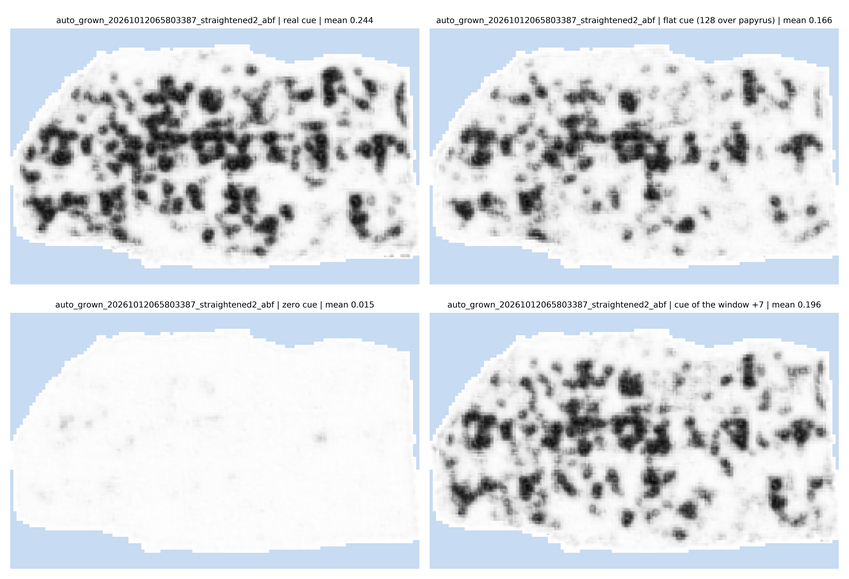

Saved /vesuvius/output/0846A/runs_iter2_iter2_asf_cue_model_epoch_10/offset_-1/cue_ablation/auto_grown_20261012065803387_straightened2_abf.png


In [12]:
# CUE ABLATION, no training: the same checkpoint on the winning sheet with only the asf_morph cue channel changed.
#   real cue                | flat cue (128 = "no information" over the papyrus)
#   zero cue (strongest "no ink" evidence) | cue of the window +7 slices away (a real map, but the wrong one for these slices)
# Regions that fade with the flat/zero cue are driven by the cue; regions that survive come from the raw slices. The model never
# saw these cues in training, so read which regions change, not the absolute probabilities.
from utils.precomputed_asf import cue_from_window

ABLATION_SWAP_SHIFT = 7


def cue_ablation(name=WINNING, preview=True):
    from utils.fast_figure import orient_display

    inputs = load_inputs(name)
    if str(C.model.input_cue) != "pre_clahe":
        raise ValueError("this checkpoint has no cue input to ablate")
    mask, height, width = inputs["mask"], *inputs["mask"].shape
    start, end = inputs["win_start"] + ABLATION_SWAP_SHIFT, inputs["win_end"] + ABLATION_SWAP_SHIFT
    swapped_path = CACHE_ROOT / "cue" / f"{PATCHES[name]['zid']}_s{start}.npy"
    if not swapped_path.is_file():
        swapped_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(swapped_path, cue_from_window(np.asarray(inputs["volume"][start:end], dtype=np.float32), mask))
    cues = {
        "flat cue (128 over papyrus)": np.where(mask, 128, 0).astype(np.uint8),
        "zero cue": np.zeros(mask.shape, dtype=np.uint8),
        f"cue of the window +{ABLATION_SWAP_SHIFT}": np.load(swapped_path, mmap_mode="r"),
    }
    offsets, method = depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)
    predict = depth_ensemble_utils.ensemble_predict(predict_tiles, offsets, method)
    results = {"real cue": PREDICTIONS[name] if name in PREDICTIONS else None}
    for label, cue in {"real cue": inputs["cue"], **cues}.items():
        if results.get(label) is not None:
            continue
        results[label] = np.asarray(predict(
            C, get_model(), inputs["volume"], mask, inputs["coords"], (0, height), (0, width), C.data.d_start, name,
            *inputs["norm"], surface_depth_map=inputs["surface_depth"], surface_confidence_map=inputs["surface_confidence"],
            surface_depth_offset=inputs["offset"], cue_map=cue,
        ), dtype=np.float32)
    panels = []
    for label, grid in results.items():
        shown = orient_display(grid, name)
        panels.append((f"{name} | {label} | mean {np.nanmean(shown):.3f}",
                       colorize(shown, "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None))
    cell = int(C.model.multitile_subtile)
    folder = OUT_DIR / "cue_ablation"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{name}.png"
    save_panel_grid([panels[:2], panels[2:]], (shown.shape[0] * cell, shown.shape[1] * cell), str(path), gap_px=24)
    if preview:
        with Image.open(path) as saved:
            display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                                 Image.Resampling.LANCZOS))
    print(f"Saved {path}")
    del inputs, results, panels, cues
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return path


cue_ablation_path = cue_ablation()


In [ ]:
# TRAIN: ABF
render("auto_grown_20260927134928530_abf")


In [ ]:
# TRAIN: 073246
render("auto_grown_20261012073244544_abf")


In [ ]:
# TRAIN: m28 (straight sheet at offset +29, -29 in VC3D)
render("auto_grown_20261012065803387_straight_abf_m28")


In [ ]:
# TRAIN: straightened2 in_1
render("auto_grown_20261012065803387_straightened2_abf_in_1")


In [ ]:
# TRAIN: straightened2 out_1
render("auto_grown_20261012065803387_straightened2_abf_out_1")


In [ ]:
# TRAIN: straightened2 out_2
render("auto_grown_20261012065803387_straightened2_abf_out_2")


In [ ]:
# TRAIN: straightened2 out_3
render("auto_grown_20261012065803387_straightened2_abf_out_3")


In [ ]:
# TRAIN: PHerc0009B (its stored surface labels, window offset 0, stored cue)
render("PHerc0009B_20250919125754")


In [ ]:
# HELD OUT: straightened2 out_4
render("auto_grown_20261012065803387_straightened2_abf_out_4")


In [ ]:
# HELD OUT: straightened2 out_5
render("auto_grown_20261012065803387_straightened2_abf_out_5")

In [ ]:
# HELD OUT: quick patch 20260926074031926
render("auto_grown_20260926074031926_abf")


In [ ]:
# HELD OUT: quick patch 20260927143929299
render("auto_grown_20260927143929299_abf")


In [ ]:
# HELD OUT: quick patch 20260927154033403
render("auto_grown_20260927154033403_abf")


In [ ]:
# Z-SCORE + CT 2x2 for the winning sheet: z-score top-k of the per-depth predictions beside three copies of the CT composite.
# Per-depth predictions are cached under output/offset_depth_sweep/<model name>/ so a different checkpoint never reuses them.
OFFSET_RANGE = (-1, 1)  # inclusive
TOPK_MEAN = 2           # mean of the k highest probabilities: 1 = max, len(range) = plain mean
ZSCORE_TOPK = 2         # strongest per-depth z-scores averaged per pixel
CORROB_K = 3            # a cell counts as corroborated when its k-th strongest depth is also high
CORROB_GAMMA = 0.5      # mid-tone lift for fully corroborated cells (1 = none; 0.5 maps 0.25 -> 0.5)
CORROB_SIGMA = 1.0      # spatial agreement, in prediction cells (one cell = 16 px)
CORROB_RAMP = (0.15, 0.45)  # k-th-depth support from no boost to full boost


def sweep_predictions(patch_name, offsets, inputs):
    """per-offset probability maps from the sweep cache; offsets missing from it are predicted and cached."""
    folder = REPO / "output" / "offset_depth_sweep" / MODEL_NAME
    folder.mkdir(parents=True, exist_ok=True)
    height, width = inputs["mask"].shape
    maps = []
    for offset in offsets:
        path = folder / f"{patch_name}_offset_{offset:+d}.npy"
        if not path.is_file():
            print(f"predicting offset {offset:+d} (not in the sweep cache)")
            prediction = predict_tiles(
                C, get_model(), inputs["volume"], inputs["mask"], inputs["coords"],
                (0, height), (0, width), C.data.d_start, f"offset_patch_d{offset:+d}", *inputs["norm"],
                surface_depth_map=inputs["surface_depth"],
                surface_confidence_map=inputs["surface_confidence"],
                surface_depth_offset=offset, cue_map=inputs["cue"],
            )
            np.save(path, np.asarray(prediction, dtype=np.float32))
        maps.append(np.load(path))
    return np.stack(maps)


def depth_composites(stack):
    """{method: (map, vmin, vmax)} for max, corroborated mid-boost, top-k mean and z-score top-k."""
    valid = np.isfinite(stack).all(axis=0)
    probability = np.clip(np.nan_to_num(stack, nan=0.5), 1e-4, 1 - 1e-4)
    ranked = np.sort(probability, axis=0)[::-1]
    top_mean = ranked[:min(TOPK_MEAN, len(ranked))].mean(axis=0)
    # corroboration: the k-th strongest depth, averaged over neighbouring cells (NaN-aware)
    k = min(CORROB_K, len(ranked))
    weight = cv2.GaussianBlur(valid.astype(np.float32), (0, 0), CORROB_SIGMA)
    support = cv2.GaussianBlur((ranked[k - 1] * valid).astype(np.float32), (0, 0), CORROB_SIGMA)
    support /= np.maximum(weight, 1e-6)
    agree = np.clip((support - CORROB_RAMP[0]) / (CORROB_RAMP[1] - CORROB_RAMP[0]), 0, 1)
    agree = agree * agree * (3 - 2 * agree)
    # lone single-depth spikes drop to the top-k mean; agreed cells get their mids lifted by the gamma curve
    corroborated = ranked[:k].mean(axis=0) ** (1 - (1 - CORROB_GAMMA) * agree)
    # each depth on its own noise scale (median/MAD of its logits), so a noisy depth cannot dominate
    logits = np.log(probability) - np.log1p(-probability)
    z = np.empty_like(logits)
    for index, depth_logits in enumerate(logits):
        values = depth_logits[valid]
        median = np.median(values)
        z[index] = (depth_logits - median) / (1.4826 * np.median(np.abs(values - median)) + 1e-6)
    z_top = np.sort(z, axis=0)[-min(ZSCORE_TOPK, len(z)):].mean(axis=0)
    nan = np.where(valid, 0.0, np.nan)
    return {
        "max": (ranked[0] + nan, 0.0, 1.0),
        "corroborated": (corroborated + nan, 0.0, 1.0),
        "topk_mean": (top_mean + nan, 0.0, 1.0),
        "zscore_top": (z_top + nan, 0.0, float(np.percentile(z_top[valid], 99.5))),
    }




def zscore_ct_grid(patch_name, offset_range=None):
    from utils.fast_figure import orient_display

    low, high = offset_range or OFFSET_RANGE
    inputs = load_inputs(patch_name)
    first = FLAT_DEPTH - (DEPTH - 1) // 2 + low
    last = FLAT_DEPTH - (DEPTH - 1) // 2 + high + DEPTH
    if low > high or first < 0 or last > inputs["volume"].shape[0]:
        raise ValueError(f"Offsets {low:+d}..{high:+d} select invalid slices {first}:{last}")
    zscore, vmin, vmax = depth_composites(sweep_predictions(patch_name, list(range(low, high + 1)), inputs))["zscore_top"]
    projection = np.asarray(inputs["volume"][first:last]).max(axis=0)
    ct = orient_display(np.clip(projection, 0, 255).astype(np.uint8) * inputs["mask"], patch_name)
    z_panel = (f"z-score top-{ZSCORE_TOPK} (0..p99.5) | d{low:+d}..{high:+d}",
               colorize(orient_display(zscore, patch_name), "gray_r", (0.78, 0.86, 0.95), vmin=vmin, vmax=vmax),
               cv2.INTER_AREA, None)
    ct_panel = (f"CT max slices {first}-{last - 1}", gray_rgb(ct), cv2.INTER_AREA, 9.362)
    folder = REPO / "output" / "offset_depth_sweep" / MODEL_NAME / "composites"
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{patch_name}_d{low:+d}_{high:+d}_zscore_ct_2x2.png"
    save_panel_grid([[z_panel, ct_panel], [ct_panel, ct_panel]], ct.shape, str(path), gap_px=24)
    print(f"Saved {path}")
    with Image.open(path) as saved:
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    del inputs, zscore, projection, ct
    gc.collect()
    return path


zscore_grid_path = zscore_ct_grid(WINNING)


In [ ]:
# SURFACE PREDICTIONS, straightened2: detect the papyrus-air surface (generate_surface_supervision.py), compute the asf_morph
# cue on the surface-relative window, and run the model on the detected surface instead of the flat depth-13 one.
import subprocess

from utils.precomputed_asf import cue_from_window

SURFACE_PRED_DIR = CACHE_ROOT / "surface_pred"


def surface_prediction_render(name="auto_grown_20261012065803387_straightened2_abf"):
    from utils.fast_figure import orient_display

    patch = PATCHES[name]
    scroll_id = str(patch["norm_id"])
    depth_path = SURFACE_PRED_DIR / scroll_id / "depth.npy"
    if not depth_path.is_file():
        subprocess.run([sys.executable, str(REPO / "generate_surface_supervision.py"), "--scroll-id", scroll_id,
                        "--output-dir", str(SURFACE_PRED_DIR), "--review-dir", str(SURFACE_PRED_DIR / "review"),
                        "--z-start", "4", "--z-end", "28"], cwd=REPO, check=True)
    surface_depth = np.load(depth_path)
    surface_confidence = np.load(SURFACE_PRED_DIR / scroll_id / "confidence.npy")
    inputs = load_inputs(name)
    mask, volume = inputs["mask"], inputs["volume"]
    if surface_depth.shape != mask.shape:
        raise ValueError(f"detected surface {surface_depth.shape} does not match the mask {mask.shape}")
    valid = (surface_depth != 255) & (surface_confidence > 0) & mask
    if not valid.any():
        raise ValueError("the surface detector found no valid columns")
    centre = np.where(valid, surface_depth.astype(np.int64), int(np.median(surface_depth[valid])))
    start = np.clip(centre - (DEPTH - 1) // 2 + int(DEPTH_OFFSET), 0, volume.shape[0] - DEPTH)
    window = np.stack([
        np.take_along_axis(volume, np.clip(start + k, 0, volume.shape[0] - 1)[None], axis=0)[0] for k in range(DEPTH)
    ]).astype(np.float32)
    cue = cue_from_window(window, mask)
    print(f"detected surface: {100 * valid.sum() / mask.sum():.1f}% of the papyrus valid, depth median "
          f"{np.median(surface_depth[valid]):.0f}, 5-95% {np.percentile(surface_depth[valid], 5):.0f}-"
          f"{np.percentile(surface_depth[valid], 95):.0f} (flat surface = {FLAT_DEPTH})")
    height, width = mask.shape
    offsets, method = depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)
    prediction = depth_ensemble_utils.ensemble_predict(predict_tiles, offsets, method)(
        C, get_model(), volume, mask, inputs["coords"], (0, height), (0, width), C.data.d_start, name, *inputs["norm"],
        surface_depth_map=surface_depth, surface_confidence_map=surface_confidence,
        surface_depth_offset=int(DEPTH_OFFSET),
        cue_map=cue if str(C.model.input_cue) == "pre_clahe" else None,
    )
    ensemble_label = depth_ensemble_utils.describe([int(DEPTH_OFFSET) + o for o in offsets], method)
    composite = np.clip(window.max(axis=0), 0, 255).astype(np.uint8) * mask
    shown_prediction, shown_composite, shown_cue = (orient_display(array, name) for array in (prediction, composite, cue))
    panels = [[
        (f"{name} | detected surface | {ensemble_label or f'offset {DEPTH_OFFSET:+d}'}",
         colorize(shown_prediction, "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None),
        ("composite of the surface-relative window", gray_rgb(shown_composite), cv2.INTER_AREA, 9.362),
        ("asf_morph cue (surface-relative window)", gray_rgb(shown_cue), cv2.INTER_AREA, None),
    ]]
    folder = OUT_DIR / "surface_prediction"
    folder.mkdir(parents=True, exist_ok=True)
    output_path = folder / f"{name}.png"
    save_panel_grid(panels, shown_composite.shape, str(output_path), gap_px=24)
    with Image.open(output_path) as saved:
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    print(f"Saved {output_path}")
    del inputs, prediction, window, composite
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return output_path


surface_prediction_render()


In [ ]:
# VIS-ONLY: remaining quick patches; individual entries above are excluded.
quick_patch_outputs = render_remaining_quick_patches()

In [ ]:
# DEPTH SWEEP -4..+4 on the winning sheet: one figure per depth offset (prediction | composite of that window).
# Predictions come from (and fill) the same per-checkpoint sweep cache as the z-score cell.
SWEEP_RANGE = (-4, 4)  # inclusive
SWEEP_DIR = REPO / "output" / "0846A" / "44depths"


def depth_sweep_figures(name=WINNING, offset_range=SWEEP_RANGE):
    from utils.fast_figure import orient_display

    low, high = offset_range
    inputs = load_inputs(name)
    first, last = FLAT_DEPTH - (DEPTH - 1) // 2 + low, FLAT_DEPTH - (DEPTH - 1) // 2 + high + DEPTH
    if low > high or first < 0 or last > inputs["volume"].shape[0]:
        raise ValueError(f"Offsets {low:+d}..{high:+d} select invalid slices {first}:{last}")
    offsets = list(range(low, high + 1))
    stack = sweep_predictions(name, offsets, inputs)
    SWEEP_DIR.mkdir(parents=True, exist_ok=True)
    paths = []
    for offset, prediction in zip(offsets, stack):
        start = FLAT_DEPTH - (DEPTH - 1) // 2 + offset
        projection = np.asarray(inputs["volume"][start:start + DEPTH]).max(axis=0)
        composite = orient_display(np.clip(projection, 0, 255).astype(np.uint8) * inputs["mask"], name)
        panels = [[
            (f"{name} | depth offset {offset:+d}",
             colorize(orient_display(prediction, name), "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None),
            (f"composite {start}-{start + DEPTH - 1}", gray_rgb(composite), cv2.INTER_AREA, 9.362),
        ]]
        path = SWEEP_DIR / f"{name}_offset_{offset:+d}.png"
        save_panel_grid(panels, composite.shape, str(path), gap_px=24)
        print(f"Saved {path}")
        paths.append(path)
    del inputs, stack
    gc.collect()
    return paths


depth_sweep_paths = depth_sweep_figures()


In [ ]:
# SHARPEN / TTA / DENOISE on the winning sheet (straightened2): does a simple input filter or test-time averaging clean the prediction?
#   base            | sharpen A (unsharp, small) | sharpen B (unsharp, wide + strong)
#   tta 3 flips     | tta 3 random rotations     | wiener denoise
# Filters act on the 8 window slices only (masked, so the papyrus edge gets no halo); the cue is recomputed from each filtered window;
# the norm stays the base sheet's. Every variant sees the same crop, a multiple of CROP_MULTIPLE, so the grids line up cell for cell.
import warnings

from scipy import ndimage as ndi
from scipy import signal

from utils.fast_figure import orient_display
from utils.precomputed_asf import cue_from_window

SHARPEN_A = (1.5, 1.0)  # unsharp mask: gaussian sigma in px, amount
SHARPEN_B = (4.0, 2.0)
WIENER_SIZE = 5
RANDOM_ROTATIONS = 3
ROTATION_SEED = 0
CROP_MULTIPLE = 64
FILTER_REGION = None  # (y0, y1, x0, x1) to try a part of the sheet, None = the whole sheet
FILTER_DIR = REPO / "output" / "0846A" / MODEL_NAME / "filter_comparison"
CELL = int(C.model.multitile_subtile)
# (forward on arrays with axes (..., y, x), inverse on the prediction grid)
FLIPS = (
    (lambda a: a[..., ::-1], lambda g: g[:, ::-1]),
    (lambda a: a[..., ::-1, :], lambda g: g[::-1]),
    (lambda a: np.rot90(a, 1, axes=(-2, -1)), lambda g: np.rot90(g, -1)),
)


def masked_blur(layer, mask_f, sigma):
    return cv2.GaussianBlur(layer * mask_f, (0, 0), sigma) / np.maximum(cv2.GaussianBlur(mask_f, (0, 0), sigma), 1e-3)


def unsharp(window, mask, sigma, amount):
    mask_f = mask.astype(np.float32)
    return np.stack([
        np.clip(layer + amount * (layer - masked_blur(layer, mask_f, sigma)), 0, 255) * mask_f for layer in window
    ])


def wiener_denoise(window, mask, size):
    mask_f = mask.astype(np.float32)
    out = []
    for layer in window:
        mean = ndi.uniform_filter(layer, size)
        variance = ndi.uniform_filter(layer * layer, size) - mean * mean
        # noise power from the papyrus only; the zero background would drag the default estimate down
        out.append(np.clip(signal.wiener(layer, size, float(variance[mask].mean())), 0, 255) * mask_f)
    return np.stack(out)


def predict_window(inputs, window, mask, name):
    """flat depth-13 prediction of an 8-slice window placed at its usual slices of an otherwise empty volume."""
    height, width = mask.shape
    volume = np.zeros((inputs["volume"].shape[0], height, width), dtype=np.uint16)
    volume[inputs["win_start"]:inputs["win_end"]] = np.clip(window, 0, 255).astype(np.uint16)
    coords = TensorboardVisualizer._gen_tile_coords(
        types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end), (0, height), (0, width), mask, z_step=DEPTH,
    )
    cue = cue_from_window(window.astype(np.float32), mask) if str(C.model.input_cue) == "pre_clahe" else None
    return predict_tiles(
        C, get_model(), volume, mask, coords, (0, height), (0, width), C.data.d_start, name, *inputs["norm"],
        surface_depth_map=np.where(mask, FLAT_DEPTH, 255).astype(np.uint8),
        surface_confidence_map=np.where(mask, 255, 0).astype(np.uint8),
        surface_depth_offset=inputs["offset"], cue_map=cue,
    )


def nan_mean(views):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(np.stack(views), axis=0)


def rotate_view(window, mask, angle):
    """rotate by `angle` degrees onto a canvas big enough to lose nothing; the padding is outside the mask."""
    height, width = mask.shape
    center = ((width - 1) / 2, (height - 1) / 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    cos, sin = abs(matrix[0, 0]), abs(matrix[0, 1])
    new_width = int(np.ceil((height * sin + width * cos) / CROP_MULTIPLE)) * CROP_MULTIPLE
    new_height = int(np.ceil((height * cos + width * sin) / CROP_MULTIPLE)) * CROP_MULTIPLE
    matrix[0, 2] += (new_width - 1) / 2 - center[0]
    matrix[1, 2] += (new_height - 1) / 2 - center[1]
    rotated_mask = cv2.warpAffine(mask.astype(np.uint8), matrix, (new_width, new_height), flags=cv2.INTER_NEAREST) > 0
    rotated = np.stack([cv2.warpAffine(layer, matrix, (new_width, new_height), flags=cv2.INTER_LINEAR) for layer in window])
    return rotated * rotated_mask, rotated_mask, matrix


def unrotate_grid(prediction, matrix, shape):
    """rotated-frame prediction grid back onto the original frame's grid; cells without papyrus coverage stay NaN."""
    valid = np.isfinite(prediction).astype(np.float32)
    up = cv2.resize(np.nan_to_num(prediction) * valid, None, fx=CELL, fy=CELL, interpolation=cv2.INTER_NEAREST)
    up_valid = cv2.resize(valid, None, fx=CELL, fy=CELL, interpolation=cv2.INTER_NEAREST)
    inverse = cv2.invertAffineTransform(matrix)
    size = (shape[1], shape[0])
    grid = (shape[1] // CELL, shape[0] // CELL)
    total = cv2.resize(cv2.warpAffine(up, inverse, size, flags=cv2.INTER_LINEAR), grid, interpolation=cv2.INTER_AREA)
    weight = cv2.resize(cv2.warpAffine(up_valid, inverse, size, flags=cv2.INTER_LINEAR), grid, interpolation=cv2.INTER_AREA)
    return np.where(weight > 0.5, total / np.maximum(weight, 1e-6), np.nan)


def filter_comparison(name=WINNING, region=FILTER_REGION):
    inputs = load_inputs(name)
    full_mask = inputs["mask"]
    y0, y1, x0, x1 = region or (0, full_mask.shape[0], 0, full_mask.shape[1])
    y1 = y0 + (y1 - y0) // CROP_MULTIPLE * CROP_MULTIPLE
    x1 = x0 + (x1 - x0) // CROP_MULTIPLE * CROP_MULTIPLE
    mask = np.ascontiguousarray(full_mask[y0:y1, x0:x1])
    window = np.asarray(inputs["volume"][inputs["win_start"]:inputs["win_end"], y0:y1, x0:x1], dtype=np.float32) * mask

    results = {"base": predict_window(inputs, window, mask, name)}
    results[f"sharpen A (unsharp sigma {SHARPEN_A[0]}, x{SHARPEN_A[1]})"] = predict_window(
        inputs, unsharp(window, mask, *SHARPEN_A), mask, name)
    results[f"sharpen B (unsharp sigma {SHARPEN_B[0]}, x{SHARPEN_B[1]})"] = predict_window(
        inputs, unsharp(window, mask, *SHARPEN_B), mask, name)
    views = [
        inverse(predict_window(inputs, np.ascontiguousarray(forward(window)), np.ascontiguousarray(forward(mask)), name))
        for forward, inverse in FLIPS
    ]
    results["tta: h-flip, v-flip, +90 rotation"] = nan_mean(views)
    views = []
    for angle in np.random.default_rng(ROTATION_SEED).uniform(0, 360, RANDOM_ROTATIONS):
        rotated, rotated_mask, matrix = rotate_view(window, mask, float(angle))
        views.append(unrotate_grid(predict_window(inputs, rotated, rotated_mask, name), matrix, mask.shape))
    results[f"tta: {RANDOM_ROTATIONS} random rotations"] = nan_mean(views)
    results[f"wiener denoise ({WIENER_SIZE}x{WIENER_SIZE})"] = predict_window(
        inputs, wiener_denoise(window, mask, WIENER_SIZE), mask, name)

    panels = []
    for label, prediction in results.items():
        shown = orient_display(prediction, name)
        values = shown[np.isfinite(shown)]
        title = f"{label} | mean {values.mean():.3f}, p99 {np.percentile(values, 99):.2f}"
        panels.append((title, colorize(shown, "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None))
        cell_hw = (shown.shape[0] * CELL, shown.shape[1] * CELL)
    FILTER_DIR.mkdir(parents=True, exist_ok=True)
    path = FILTER_DIR / f"{name}.png"
    save_panel_grid([panels[:3], panels[3:]], cell_hw, str(path), gap_px=24)
    with Image.open(path) as saved:
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    print(f"Saved {path}")
    del window, results, views, panels
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return path


filter_comparison_path = filter_comparison()


In [ ]:
# DENOISING VARIATIONS on the winning sheet. Needs only the setup cells.
#   base                       | strong wiener (5x5, full noise), depths -1/0/+1, mid-boost | weak wiener (3x3, 0.25x noise), 1 depth
#   weak wiener, 3 depths      | strong wiener 3 depths, restored where raw depths agree    | z-smooth + bilateral (edge-preserving), 3 depths
# Every depth d gets its own window (slices win_start+d ..) filtered, then predicted at surface offset +d; depths combine with mid-boost.
from scipy import ndimage as ndi
from scipy import signal

from utils.fast_figure import orient_display
from utils.precomputed_asf import cue_from_window

CROP_MULTIPLE = 64
CELL = int(C.model.multitile_subtile)
DENOISE_DEPTHS = (-1, 0, 1)
STRONG = (5, 1.0)           # wiener (size, noise-power scale)
WEAK = (3, 0.25)
AGREE_RAMP = (0.25, 0.6)    # min raw probability over the depths: no restore -> full restore of the unfiltered prediction
BILATERAL = (5, 25.0, 3.0)  # diameter, sigma in grey levels, sigma in px
Z_SIGMA = 1.0               # smoothing across the 8 slices of a window
DENOISE_DIR = REPO / "output" / "0846A" / MODEL_NAME / "denoise_variations"


def wiener_scaled(window, mask, size, scale):
    mask_f = mask.astype(np.float32)
    out = []
    for layer in window:
        mean = ndi.uniform_filter(layer, size)
        variance = ndi.uniform_filter(layer * layer, size) - mean * mean
        out.append(np.clip(signal.wiener(layer, size, float(variance[mask].mean()) * scale), 0, 255) * mask_f)
    return np.stack(out)


def zsmooth_bilateral(window, mask):
    mask_f = mask.astype(np.float32)
    smoothed = ndi.gaussian_filter1d(window, Z_SIGMA, axis=0, mode="nearest")
    return np.stack([cv2.bilateralFilter(np.ascontiguousarray(layer), *BILATERAL) * mask_f for layer in smoothed])


def predict_shifted(inputs, window, mask, name, shift):
    """prediction for a window taken `shift` slices from the usual one, at surface offset +shift."""
    height, width = mask.shape
    volume = np.zeros((inputs["volume"].shape[0], height, width), dtype=np.uint16)
    volume[inputs["win_start"] + shift:inputs["win_end"] + shift] = np.clip(window, 0, 255).astype(np.uint16)
    coords = TensorboardVisualizer._gen_tile_coords(
        types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end), (0, height), (0, width), mask, z_step=DEPTH,
    )
    cue = cue_from_window(window.astype(np.float32), mask) if str(C.model.input_cue) == "pre_clahe" else None
    return predict_tiles(
        C, get_model(), volume, mask, coords, (0, height), (0, width), C.data.d_start, name, *inputs["norm"],
        surface_depth_map=np.where(mask, FLAT_DEPTH, 255).astype(np.uint8),
        surface_confidence_map=np.where(mask, 255, 0).astype(np.uint8),
        surface_depth_offset=inputs["offset"] + shift, cue_map=cue,
    )


def denoise_variations(name=WINNING):
    inputs = load_inputs(name)
    full_mask = inputs["mask"]
    y1 = full_mask.shape[0] // CROP_MULTIPLE * CROP_MULTIPLE
    x1 = full_mask.shape[1] // CROP_MULTIPLE * CROP_MULTIPLE
    mask = np.ascontiguousarray(full_mask[:y1, :x1])
    windows = {
        d: np.asarray(inputs["volume"][inputs["win_start"] + d:inputs["win_end"] + d, :y1, :x1], dtype=np.float32) * mask
        for d in DENOISE_DEPTHS
    }

    def run(filter_fn, depths):
        stack = [predict_shifted(inputs, filter_fn(windows[d]) if filter_fn else windows[d], mask, name, d) for d in depths]
        return stack[0] if len(stack) == 1 else depth_ensemble_utils.combine(np.stack(stack), "mid-boost"), np.stack(stack)

    strong = lambda w: wiener_scaled(w, mask, *STRONG)
    weak = lambda w: wiener_scaled(w, mask, *WEAK)
    base, _ = run(None, (0,))
    raw_ens, raw_stack = run(None, DENOISE_DEPTHS)
    strong_ens, _ = run(strong, DENOISE_DEPTHS)
    weak_one, _ = run(weak, (0,))
    weak_ens, _ = run(weak, DENOISE_DEPTHS)
    new_filter, _ = run(lambda w: zsmooth_bilateral(w, mask), DENOISE_DEPTHS)

    # trust the unfiltered prediction only where every depth already sees ink
    agree = np.clip((np.nanmin(raw_stack, axis=0) - AGREE_RAMP[0]) / (AGREE_RAMP[1] - AGREE_RAMP[0]), 0, 1)
    agree = agree * agree * (3 - 2 * agree)
    restored = strong_ens + (raw_ens - strong_ens) * agree

    results = {
        "base": base,
        f"wiener {STRONG[0]}x{STRONG[0]}, d-1..+1 mid-boost": strong_ens,
        f"weak wiener {WEAK[0]}x{WEAK[0]} x{WEAK[1]} noise, 1 depth": weak_one,
        "weak wiener, d-1..+1 mid-boost": weak_ens,
        "strong wiener + raw restored where depths agree": restored,
        "z-smooth + bilateral, d-1..+1 mid-boost": new_filter,
    }
    panels = []
    for label, prediction in results.items():
        shown = orient_display(prediction, name)
        values = shown[np.isfinite(shown)]
        title = f"{label} | mean {values.mean():.3f}, p99 {np.percentile(values, 99):.2f}"
        panels.append((title, colorize(shown, "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None))
        cell_hw = (shown.shape[0] * CELL, shown.shape[1] * CELL)
    DENOISE_DIR.mkdir(parents=True, exist_ok=True)
    path = DENOISE_DIR / f"{name}.png"
    save_panel_grid([panels[:3], panels[3:]], cell_hw, str(path), gap_px=24)
    with Image.open(path) as saved:
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    print(f"Saved {path}")
    del windows, results, panels, raw_stack
    gc.collect()
    if C.device == "cuda":
        torch.cuda.empty_cache()
    return path


denoise_variations_path = denoise_variations()

In [ ]:
# NOISE vs INK: 6 more methods + a model fusion on the winning sheet. Needs only the setup cells.
# Per-depth (-3..+3) predictions are cached under output/0846A/depth_stacks/ and reused: asf_cue raw, asf_cue on a weak-wiener input,
# and the fusion model (depth_mil) raw. Every method below is a cheap post-process of those stacks.
#   base (asf_cue, d0)                            | depth_mil d0 (cleanest, loses ink)           | FUSION: asf_cue gated by depth_mil, noisy-or
#   1 7-depth mean, peak restored                 | 2 soft-AND: sqrt(geomean d-1..1 x max d-3..3) | 3 logit mean d-2..2, x1.25 gain
#   4 bilateral on 3-depth mid-boost, peak restored | 5 hysteresis: keep only blobs touching strong ink | 6 weak wiener, 7-depth mid-boost
from scipy import ndimage as ndi
from scipy import signal

from utils.fast_figure import orient_display
from utils.precomputed_asf import cue_from_window

FUSION_CHECKPOINT = "/vesuvius/models/runs_iter2/iter2_idea2_depth_mil/model_epoch_10.pth"
STACK_DEPTHS = tuple(range(-3, 4))
CENTER = STACK_DEPTHS.index(0)
CROP_MULTIPLE = 64
CELL = int(C.model.multitile_subtile)
WEAK = (3, 0.25)             # wiener (size, noise-power scale)
BILATERAL_GRID = (5, 0.12, 2.0)  # diameter, sigma in probability, sigma in cells
HYST = (0.15, 0.55)          # grow into cells above low only when the blob holds a cell above high
HYST_FLOOR = 0.3             # weight kept by blobs without strong ink
LOGIT_GAIN = 1.25
FUSION_FLOOR = 0.25          # asf_cue weight where depth_mil sees nothing nearby
FUSION_GATE = (0.05, 0.35)   # dilated depth_mil probability: gate floor -> fully open
STACK_DIR = REPO / "output" / "0846A" / "depth_stacks"
METHODS_DIR = REPO / "output" / "0846A" / MODEL_NAME / "denoise_methods"


def wiener_scaled(window, mask, size, scale):
    mask_f = mask.astype(np.float32)
    out = []
    for layer in window:
        mean = ndi.uniform_filter(layer, size)
        variance = ndi.uniform_filter(layer * layer, size) - mean * mean
        out.append(np.clip(signal.wiener(layer, size, float(variance[mask].mean()) * scale), 0, 255) * mask_f)
    return np.stack(out)


def build_config(checkpoint):
    run_config, _ = resolve_run_config(checkpoint)
    cfg = Config()
    for section in ("data", "model"):
        for key, value in run_config[section].items():
            if section == "data" and key == "scrolls":
                cfg.data.scrolls = [ScrollConfig(**item) for item in value]
            elif key != "probe_rois" and hasattr(getattr(cfg, section), key):
                setattr(getattr(cfg, section), key, value)
    cfg.model.compile_model = False
    cfg.tra.supcon = False
    cfg.tra.dann = False
    cfg.device = C.device
    cfg.data.eval_stride = EVAL_STRIDE
    cfg.data.surface_window_offset = int(DEPTH_OFFSET)
    cfg.data.surface_window_offset_by_scroll = {}
    cfg.data.zarr_path = str(ZARR_DIR)
    return cfg


def load_fusion_model():
    path = Path(FUSION_CHECKPOINT).resolve()
    cfg = build_config(path)
    if str(cfg.data.norm_mode) != NORM_MODE or int(cfg.data.depth) != DEPTH:
        raise ValueError("fusion model needs the same normalization and depth as the main model")
    model, _ = create_model(cfg)
    state = torch.load(path, map_location="cpu", weights_only=True)
    state = state.get("model_state_dict", state.get("state_dict", state))
    state = {key.removeprefix("module.").removeprefix("_orig_mod."): value for key, value in state.items()}
    state = {key: value for key, value in state.items() if not key.startswith(("supcon_head.", "domain_head."))}
    model.load_state_dict(state, strict=True)
    model.eval()
    return cfg, model, f"{path.parent.parent.name}_{path.parent.name}_{path.stem}"


def predict_with(cfg, model, inputs, window, mask, name, shift):
    """prediction for a window taken `shift` slices from the usual one, at surface offset +shift."""
    height, width = mask.shape
    volume = np.zeros((inputs["volume"].shape[0], height, width), dtype=np.uint16)
    volume[inputs["win_start"] + shift:inputs["win_end"] + shift] = np.clip(window, 0, 255).astype(np.uint16)
    coords = TensorboardVisualizer._gen_tile_coords(
        types.SimpleNamespace(c=cfg), (cfg.data.d_start, cfg.data.d_end), (0, height), (0, width), mask, z_step=DEPTH,
    )
    cue = cue_from_window(window.astype(np.float32), mask) if str(cfg.model.input_cue) == "pre_clahe" else None
    return predict_tiles(
        cfg, model, volume, mask, coords, (0, height), (0, width), cfg.data.d_start, name, *inputs["norm"],
        surface_depth_map=np.where(mask, FLAT_DEPTH, 255).astype(np.uint8),
        surface_confidence_map=np.where(mask, 255, 0).astype(np.uint8),
        surface_depth_offset=inputs["offset"] + shift, cue_map=cue,
    )


def depth_stack(name, cfg, model, model_name, tag, filter_fn, inputs, mask):
    """(depths, h, w) predictions; each depth is cached on disk so a rerun only fills what is missing."""
    STACK_DIR.mkdir(parents=True, exist_ok=True)
    maps = []
    for shift in STACK_DEPTHS:
        path = STACK_DIR / f"{name}_{model_name}_{tag}_d{shift:+d}.npy"
        if not path.is_file():
            print(f"predicting {model_name} / {tag} / depth {shift:+d}")
            window = np.asarray(inputs["volume"][inputs["win_start"] + shift:inputs["win_end"] + shift,
                                                 :mask.shape[0], :mask.shape[1]], dtype=np.float32) * mask
            if filter_fn:
                window = filter_fn(window)
            np.save(path, np.asarray(predict_with(cfg, model, inputs, window, mask, name, shift), dtype=np.float32))
        maps.append(np.load(path))
    return np.stack(maps)


def smoothstep(x, low, high):
    t = np.clip((x - low) / (high - low), 0, 1)
    return t * t * (3 - 2 * t)


def denoise_methods(name=WINNING):
    inputs = load_inputs(name)
    full_mask = inputs["mask"]
    mask = np.ascontiguousarray(full_mask[:full_mask.shape[0] // CROP_MULTIPLE * CROP_MULTIPLE,
                                          :full_mask.shape[1] // CROP_MULTIPLE * CROP_MULTIPLE])
    fusion_cfg, fusion_model, fusion_name = load_fusion_model()
    raw = depth_stack(name, C, get_model(), MODEL_NAME, "raw", None, inputs, mask)
    weak = depth_stack(name, C, get_model(), MODEL_NAME, "weakwiener", lambda w: wiener_scaled(w, mask, *WEAK), inputs, mask)
    mil = depth_stack(name, fusion_cfg, fusion_model, fusion_name, "raw", None, inputs, mask)
    del fusion_model
    if C.device == "cuda":
        torch.cuda.empty_cache()

    valid = np.isfinite(raw).all(axis=0) & np.isfinite(mil).all(axis=0)
    finish = lambda p: np.where(valid, np.clip(p, 0, 1), np.nan)
    fill = lambda p: np.where(valid, np.nan_to_num(p, nan=0.0), 0.0)
    combine = depth_ensemble_utils.combine
    base = fill(raw[CENTER])
    target = float(np.percentile(base[valid], 99))
    match_peak = lambda p: p * target / max(float(np.percentile(p[valid], 99)), 1e-6)

    mid3 = fill(combine(raw[CENTER - 1:CENTER + 2], "mid-boost"))
    mid7 = fill(combine(raw, "mid-boost"))
    raw_f = np.clip(np.nan_to_num(raw, nan=0.0), 1e-4, 1 - 1e-4)

    m1 = match_peak(raw_f.mean(axis=0))
    geomean = np.exp(np.log(raw_f[CENTER - 1:CENTER + 2]).mean(axis=0))
    m2 = match_peak(np.sqrt(geomean * raw_f.max(axis=0)))
    logits = (np.log(raw_f) - np.log1p(-raw_f))[CENTER - 2:CENTER + 3].mean(axis=0)
    m3 = 1 / (1 + np.exp(-LOGIT_GAIN * logits))
    m4 = match_peak(cv2.bilateralFilter(mid3.astype(np.float32), *BILATERAL_GRID))
    labels, _ = ndi.label(mid7 > HYST[0])
    strong = np.unique(labels[mid7 > HYST[1]])
    keep = cv2.GaussianBlur(np.isin(labels, strong[strong > 0]).astype(np.float32), (0, 0), 1.0)
    m5 = mid7 * (HYST_FLOOR + (1 - HYST_FLOOR) * keep)
    m6 = fill(combine(weak, "mid-boost"))

    # depth_mil is clean but misses ink: it only decides how much to trust asf_cue nearby, and its own ink is added back (noisy-or)
    mil_mid3 = fill(combine(mil[CENTER - 1:CENTER + 2], "mid-boost"))
    near_mil = cv2.GaussianBlur(ndi.maximum_filter(mil_mid3, size=3).astype(np.float32), (0, 0), 1.0)
    gate = FUSION_FLOOR + (1 - FUSION_FLOOR) * smoothstep(near_mil, *FUSION_GATE)
    fused = 1 - (1 - mid3 * gate) * (1 - mil_mid3)

    results = {
        "base (asf_cue, d0)": base,
        "depth_mil d0": fill(mil[CENTER]),
        "FUSION: asf_cue gated by depth_mil + noisy-or": fused,
        "1: 7-depth mean, peak restored": m1,
        "2: soft-AND geomean d-1..1 x max d-3..3": m2,
        f"3: logit mean d-2..2, gain x{LOGIT_GAIN}": m3,
        "4: bilateral on 3-depth mid-boost": m4,
        f"5: hysteresis {HYST[0]}/{HYST[1]} on 7-depth mid-boost": m5,
        f"6: weak wiener {WEAK[0]}x{WEAK[0]} x{WEAK[1]}, 7-depth mid-boost": m6,
    }
    panels = []
    for label, prediction in results.items():
        shown = orient_display(finish(prediction), name)
        values = shown[np.isfinite(shown)]
        title = f"{label} | mean {values.mean():.3f}, p99 {np.percentile(values, 99):.2f}"
        panels.append((title, colorize(shown, "gray_r", (0.78, 0.86, 0.95)), cv2.INTER_NEAREST, None))
        cell_hw = (shown.shape[0] * CELL, shown.shape[1] * CELL)
    METHODS_DIR.mkdir(parents=True, exist_ok=True)
    path = METHODS_DIR / f"{name}.png"
    save_panel_grid([panels[0:3], panels[3:6], panels[6:9]], cell_hw, str(path), gap_px=24)
    with Image.open(path) as saved:
        display(saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE), max(1, saved.height // PREVIEW_DOWNSCALE)),
                             Image.Resampling.LANCZOS))
    print(f"Saved {path}")
    del raw, weak, mil, results, panels
    gc.collect()
    return path


denoise_methods_path = denoise_methods()
